<a href="https://colab.research.google.com/github/Dangidhruvil07/Sessions-of-Datasciences/blob/main/5_Task_22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

pd.options.display.max_columns = None

### `Question-1:`

The dataset is based on NFTs. This is quite large. So, when you will read the dataset, you have to wait. The link of the dataset: https://tinyurl.com/2pfhncqw

Your task is to make a pivote table by using the columns "verification_status", "contract_type", "rarity_score" and "last_sale_price" to find out the total values.

In [ ]:
# code here
# df = pd.read_csv("https://tinyurl.com/2pfhncqw")
# df.head()

### `Question-2:`

You are given a dataset about the cars' price and miles driven of different cars throughout the different years. The link of the dataset: https://tinyurl.com/2r24n45l. Your tasks are
- make a pivot table of the brands (the required brands are given below) from the "Year" 2018 to the year 2022 in which the "Price" is shown as average values and "Miles" are in median values. In this pivote table, every row represents a particular brand and each column represents either average "Price" of a partucular year or median values of "Miles" of a particular year.
- At the end plot a kde chart for the "Price" and "Miles" by using your pivot table.

There are some challenges to solve this task:
- There is no column that is represented to the brand name of the car. You have to find out on your own.
- Some values of "Years" column are misleading. You have to reset this column too that every value should tell a valid meaning.

In [ ]:
# code here
df = pd.read_csv("https://tinyurl.com/2r24n45l")
df.head()

,Name,Year,Miles,Price
0,Chevrolet Trax,2018,41946,16990
1,GMC Terrain,2020,45328,23990
2,Jeep Wrangler,2012,81068,21590
3,Jeep Renegade,2019,35372,21590
4,BMW X,20173,68992,22990


In [ ]:
df['Brand_Name'] = df['Name'].str.split(" ").str[0]
df.head()

,Name,Year,Miles,Price,Brand_Name
0,Chevrolet Trax,2018,41946,16990,Chevrolet
1,GMC Terrain,2020,45328,23990,GMC
2,Jeep Wrangler,2012,81068,21590,Jeep
3,Jeep Renegade,2019,35372,21590,Jeep
4,BMW X,20173,68992,22990,BMW


In [ ]:
df['Brand_Name'].unique()

array(['Chevrolet', 'GMC', 'Jeep', 'BMW', 'Buick', 'Chrysler', 'Subaru',
       'Mitsubishi', 'Toyota', 'Nissan', 'Lincoln', 'Lexus', 'Dodge',
       'Ford', 'MAZDA', 'Volkswagen', 'Honda', 'FIAT', 'Hyundai', 'Kia',
       'Acura', 'INFINITI', 'Scion', 'Audi', 'Alfa', 'MINI', 'Cadillac',
       'Ram', 'Mercedes-Benz', 'Volvo', 'smart', 'Land', 'Tesla',
       'Jaguar', 'Polestar', 'Porsche', 'Genesis', 'Maserati', 'Pontiac',
       'Saturn'], dtype=object)

In [ ]:
df['Year'].unique()
df['Year'].value_counts()

,count
Year,
2015,2542
2019,2281
2017,2152
2016,2107
2014,2053
...,...
2019150,1
201770,1
20132,1


In [ ]:
df['Year'] = df['Year'].astype(str).str[:4].astype(int)
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Name        22000 non-null  object
 1   Year        22000 non-null  int64 
 2   Miles       22000 non-null  int64 
 3   Price       22000 non-null  int64 
 4   Brand_Name  22000 non-null  object
dtypes: int64(3), object(2)
memory usage: 859.5+ KB


In [ ]:
df = df[df['Year'].isin([2018, 2019, 2020, 2021, 2022])]
df.head()

,Name,Year,Miles,Price,Brand_Name
0,Chevrolet Trax,2018,41946,16990,Chevrolet
1,GMC Terrain,2020,45328,23990,GMC
3,Jeep Renegade,2019,35372,21590,Jeep
5,Buick Encore,2019,47973,18590,Buick
24,Mitsubishi Eclipse Cross,2018,85475,16990,Mitsubishi


In [ ]:
df['Brand_Name'].value_counts()


,count
Brand_Name,
Nissan,1265
Toyota,875
Kia,745
Ford,693
Chevrolet,633
Jeep,522
Honda,484
Hyundai,458
Dodge,216


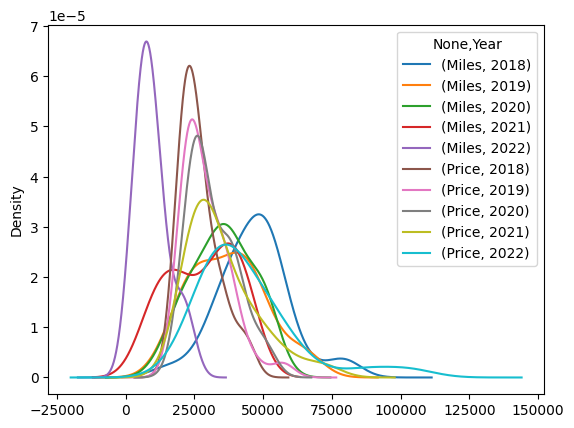

In [ ]:
temp = pd.pivot_table(df, index='Brand_Name', columns='Year', values=['Price', 'Miles'], aggfunc={'Price':'mean','Miles':'median'})
temp.plot(kind='kde')
plt.show()

In [ ]:
temp.head()

Miles                                             Price  \
Year           2018     2019     2020     2021     2022          2018   
Brand_Name                                                              
Acura       32516.0  50959.0  30894.0  10922.0      NaN  25323.333333   
Alfa        38908.0  20928.0      NaN      NaN      NaN  28490.000000   
Audi        49762.0  50169.5  30423.5  11205.0  20917.0  30345.555556   
BMW         39269.0  36306.0  23171.0  19978.0   3780.0  31762.093023   
Buick       50702.0  41152.0  36626.0  39884.0    372.0  21516.254545   

                                                               
Year                2019          2020          2021     2022  
Brand_Name                                                     
Acura       34496.777778  37590.000000  43856.666667      NaN  
Alfa        30475.714286           NaN           NaN      NaN  
Audi        28590.000000  32490.000000  71990.000000  39590.0  
BMW         33280.909091  39811.083333  37062.727273  57030.0  
Buick       21033.632653  24141.947368  25796.842105  26940.0

### `Question-3:`

You are given a dataset of **Daily Power Generation in India** of regional wise of all Power Stations. Link of the dataset: https://tinyurl.com/2nq6kugt

Task
- In this dataset, there are many columns. Two of them are `Actual(MU)` and `Excess(+) / Shortfall (-)`. `Actual(MU)` represents the actual power generation. `Excess(+) / Shortfall (-)` tells is that generated power is excess or shortfall for that particular day of a power station. You have to find out what should be the actual power generation required for that day by the power stations that there would not be any excess or shorfall power. For the result, make a new column.
- Find out the month of the day and store it as a new column.
- Find out top 10 frequently appeared power stations in this dataframe.
- Next create a pivot table of which every row represents a power station and every column represents a month in a order. Like January, February, March...
- It is hard to get inside if you look through the only pivot table. So plot the pivot table.

In [ ]:
# code here
df = pd.read_csv("https://tinyurl.com/2nq6kugt")
df.head()

,Dates,Power Station,Monitored Cap.(MW),Total Cap. Under Maintenace (MW),Planned Maintanence (MW),Forced Maintanence(MW),Other Reasons (MW),Programme or Expected(MU),Actual(MU),Excess(+) / Shortfall (-),Deviation
0,2017-09-01,Delhi,2235.4,135.00,0.00,135.0,0,13,18,5.00,0.0
1,2017-09-01,Haryana,2720.0,2470.00,0.00,2470.0,0,28,7,-21.80,0.0
2,2017-09-01,Himachal Pradesh,3378.0,379.00,0.00,231.0,0,40,46,5.63,0.0
3,2017-09-01,Jammu and Kashmir,1285.0,150.00,0.00,0.0,0,14,23,9.43,0.0
4,2017-09-01,Punjab,3826.3,2697.65,77.65,2620.0,0,39,17,-21.69,0.0


In [ ]:
df['Actual_Required'] =df['Actual(MU)'] - df['Excess(+) / Shortfall (-)']
df.head()

,Dates,Power Station,Monitored Cap.(MW),Total Cap. Under Maintenace (MW),Planned Maintanence (MW),Forced Maintanence(MW),Other Reasons (MW),Programme or Expected(MU),Actual(MU),Excess(+) / Shortfall (-),Deviation,Actual_Required
0,2017-09-01,Delhi,2235.4,135.00,0.00,135.0,0,13,18,5.00,0.0,13.00
1,2017-09-01,Haryana,2720.0,2470.00,0.00,2470.0,0,28,7,-21.80,0.0,28.80
2,2017-09-01,Himachal Pradesh,3378.0,379.00,0.00,231.0,0,40,46,5.63,0.0,40.37
3,2017-09-01,Jammu and Kashmir,1285.0,150.00,0.00,0.0,0,14,23,9.43,0.0,13.57
4,2017-09-01,Punjab,3826.3,2697.65,77.65,2620.0,0,39,17,-21.69,0.0,38.69


In [ ]:
df['Dates'] = pd.to_datetime(df['Dates'])
df['Month_name'] = df['Dates'].dt.month_name()
df.head()

,Dates,Power Station,Monitored Cap.(MW),Total Cap. Under Maintenace (MW),Planned Maintanence (MW),Forced Maintanence(MW),Other Reasons (MW),Programme or Expected(MU),Actual(MU),Excess(+) / Shortfall (-),Deviation,Actual_Required,Month_name
0,2017-09-01,Delhi,2235.4,135.00,0.00,135.0,0,13,18,5.00,0.0,13.00,September
1,2017-09-01,Haryana,2720.0,2470.00,0.00,2470.0,0,28,7,-21.80,0.0,28.80,September
2,2017-09-01,Himachal Pradesh,3378.0,379.00,0.00,231.0,0,40,46,5.63,0.0,40.37,September
3,2017-09-01,Jammu and Kashmir,1285.0,150.00,0.00,0.0,0,14,23,9.43,0.0,13.57,September
4,2017-09-01,Punjab,3826.3,2697.65,77.65,2620.0,0,39,17,-21.69,0.0,38.69,September


In [ ]:
df['Power Station'].value_counts().head(10)

,count
Power Station,
NTPC Ltd.,9570
NHPC,5742
NPCIL,5742
GMR ENERG,5742
APL,3828
JPPVL,3828
IBPIL,3828
TATA PCL,3828
JSWEL,3828


In [ ]:
months = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]
df['Month_name'] = pd.Categorical(
    df['Month_name'],
    categories=months,
    ordered=True
)

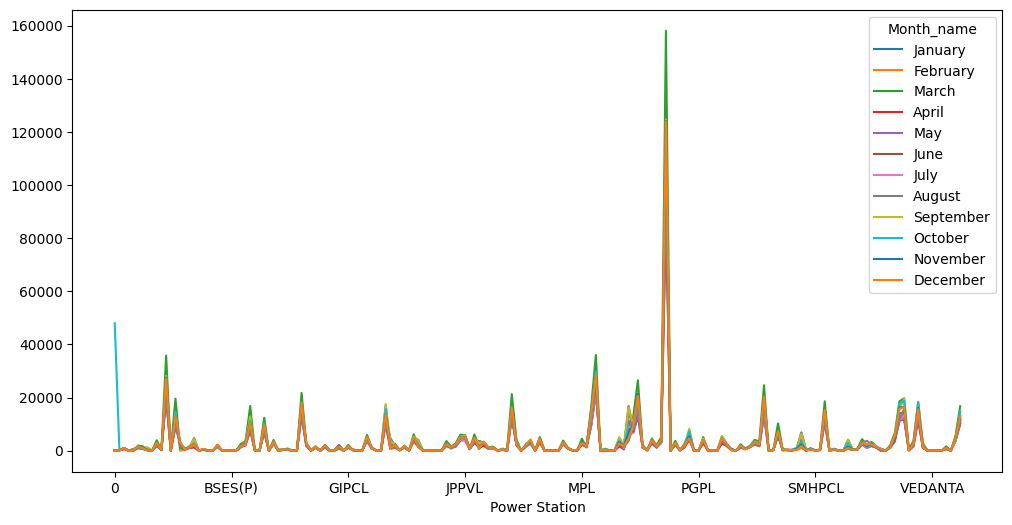

In [ ]:
pd.pivot_table(df, index='Power Station', columns='Month_name', values='Actual_Required', aggfunc='sum',observed=False).plot(kind = 'line',figsize=(12,6))
plt.show()

###`Q-4` You are given a file `question-answer.csv`. Your task is to make a dataframe from it with two columns - `question` and `answers`.

* Questions in the file start from `Q<number>`; E.g.  `Q1` denotes question no. `1`
* Answers starts from `Ans<number>`; Eg. `Ans1` denotes answer of question no `1`
* MAke sure you look at columns name carefully

CSV File - "https://drive.google.com/file/d/10rmV3XrVtzpDTtYZF3UtCdcU0ajBJjGY/view?usp=share_link"

In [ ]:
# code here
df = pd.read_csv("https://drive.google.com/uc?export=download&id=10rmV3XrVtzpDTtYZF3UtCdcU0ajBJjGY")
df.head()

,Unnamed: 0,2
0,0,Q1-What is Data Science?
1,1,"Ans1-Data Science combines statistics, maths, ..."
2,2,Q2-2. How is logistic regression done?
3,3,Ans2-Logistic regression measures the relation...
4,4,Q3-How do you build a random forest model?


In [ ]:
df.columns

Index(['Unnamed: 0', '2'], dtype='object')

In [ ]:
df['Ans'] = df[df['2'].str.startswith('Ans')]['2']
df.head()

,Unnamed: 0,2,Ans
0,0,Q1-What is Data Science?,NaN
1,1,"Ans1-Data Science combines statistics, maths, ...","Ans1-Data Science combines statistics, maths, ..."
2,2,Q2-2. How is logistic regression done?,NaN
3,3,Ans2-Logistic regression measures the relation...,Ans2-Logistic regression measures the relation...
4,4,Q3-How do you build a random forest model?,NaN


In [ ]:
df['Question'] = df[df['2'].str.startswith('Q')]['2']
df.head()

,Unnamed: 0,2,Ans,Question
0,0,Q1-What is Data Science?,NaN,Q1-What is Data Science?
1,1,"Ans1-Data Science combines statistics, maths, ...","Ans1-Data Science combines statistics, maths, ...",NaN
2,2,Q2-2. How is logistic regression done?,NaN,Q2-2. How is logistic regression done?
3,3,Ans2-Logistic regression measures the relation...,Ans2-Logistic regression measures the relation...,NaN
4,4,Q3-How do you build a random forest model?,NaN,Q3-How do you build a random forest model?


In [ ]:
df['Ans'] = df['Ans'].str.replace(r'^Ans\d+-',"",regex=True)
df['Question'] = df['Question'].str.replace(r'^Q\d+-',"",regex=True)

In [ ]:
df.head()

,Unnamed: 0,2,Ans,Question
0,0,Q1-What is Data Science?,NaN,What is Data Science?
1,1,"Ans1-Data Science combines statistics, maths, ...","Data Science combines statistics, maths, speci...",NaN
2,2,Q2-2. How is logistic regression done?,NaN,2. How is logistic regression done?
3,3,Ans2-Logistic regression measures the relation...,Logistic regression measures the relationship ...,NaN
4,4,Q3-How do you build a random forest model?,NaN,How do you build a random forest model?


In [ ]:
df['Ans'] = df['Ans'].shift(-1)
df.head(3)

,Unnamed: 0,2,Ans,Question
0,0,Q1-What is Data Science?,"Data Science combines statistics, maths, speci...",What is Data Science?
1,1,"Ans1-Data Science combines statistics, maths, ...",NaN,NaN
2,2,Q2-2. How is logistic regression done?,Logistic regression measures the relationship ...,2. How is logistic regression done?


In [ ]:
df.dropna(subset=['Question','Ans']).inplace = True

In [ ]:
df = df[['Question', 'Ans']]
df.head()

,Question,Ans
0,What is Data Science?,"Data Science combines statistics, maths, speci..."
1,NaN,NaN
2,2. How is logistic regression done?,Logistic regression measures the relationship ...
3,NaN,NaN
4,How do you build a random forest model?,A random forest is built up of a number of dec...


###`Q-5`: Print Question and answer of those questions which does not contains any question mark (`?`).


In [ ]:
# code here
df[~df['Question'].str.contains(r'\?',regex=True,na = False)]

,Question,Ans
1,NaN,NaN
3,NaN,NaN
5,NaN,NaN
7,NaN,NaN
9,NaN,NaN
11,NaN,NaN
13,NaN,NaN
15,NaN,NaN
17,NaN,NaN
19,NaN,None


###`Q 6-10` LOG and EMPLOYEE
6. Show `activity` details month wise. Show count for each `activity`
7. Find employee who did most `activity` in January month.
8. Employee who have worked most no of times on Weekends.
9. Which activity is logged most on buisness days.
10. Week Days wise activity table.
```
log_file = pd.read_csv("https://docs.google.com/spreadsheets/d/e/2PACX-1vT-OMrmmNdOTM-B5f5F1EpCutMVG230UZiLvqlsg0NIKUKR3yrqiI2r1pEX-LvSEk-3WwySPYtvbBC-/pub?gid=1937029224&single=true&output=csv")
employee = pd.read_csv("https://docs.google.com/spreadsheets/d/e/2PACX-1vQ5AuFqRjSZVBKm5zyDxquX6utubq1DJKkYDI70vjeidAnyAu70KMSYpMYzeVSNVTeUIJBpfF6jU5E6/pub?gid=798824749&single=true&output=csv")

```

Note(for common field):- Employee file has `EMPLOYEE_ID` and LOG file has `emp_id`

In [ ]:
# code here
log_file = pd.read_csv("https://docs.google.com/spreadsheets/d/e/2PACX-1vT-OMrmmNdOTM-B5f5F1EpCutMVG230UZiLvqlsg0NIKUKR3yrqiI2r1pEX-LvSEk-3WwySPYtvbBC-/pub?gid=1937029224&single=true&output=csv")
employee = pd.read_csv("https://docs.google.com/spreadsheets/d/e/2PACX-1vQ5AuFqRjSZVBKm5zyDxquX6utubq1DJKkYDI70vjeidAnyAu70KMSYpMYzeVSNVTeUIJBpfF6jU5E6/pub?gid=798824749&single=true&output=csv")

In [ ]:
log_file.head(5)
# employee.head(5)

,Log_ID,dt,dept,emp_id,activity,eqpt
0,1000,2022-01-07,Dept6,115,Cleaning,UPS
1,1001,2022-01-08,Dept4,105,Cleaning,Generator
2,1002,2022-01-09,Dept3,112,Inspection,CPU
3,1003,2022-01-10,Dept4,120,Inspection,UPS
4,1004,2022-01-11,Dept3,138,Checking,Battery


In [ ]:
log_file['dt'] = pd.to_datetime(log_file['dt'])
log_file['month'] = log_file['dt'].dt.month_name()
log_file.groupby('month')['activity'].value_counts()

month      activity  
April      Cleaning      11
           Inspection     9
           Checking       5
           Repair         5
August     Cleaning      10
           Inspection     9
           Checking       8
           Repair         4
December   Inspection    12
           Cleaning       7
           Checking       6
           Repair         6
February   Repair        10
           Checking       7
           Cleaning       7
           Inspection     4
January    Cleaning      10
           Inspection     9
           Checking       7
           Repair         5
July       Inspection    14
           Checking       6
           Cleaning       6
           Repair         5
June       Repair        10
           Inspection     8
           Cleaning       7
           Checking       5
March      Repair        12
           Checking       8
           Cleaning       6
           Inspection     5
May        Repair        11
           Cleaning       8
           Inspection     7
           Checking       5
November   Cleaning       9
           Checking       8
           Repair         7
           Inspection     6
October    Checking      13
           Repair         9
           Inspection     5
           Cleaning       4
September  Inspection    12
           Checking       8
           Repair         7
           Cleaning       3
Name: count, dtype: int64

In [ ]:
log_file.groupby('month')['emp_id'].value_counts().loc['January'].sort_values(ascending=False).head(1)

,count
emp_id,
122,3


In [ ]:
log_file.head()
employee.head()
# employee.rename(columns={'EMPLOYEE_ID':'emp_id'},inplace=True)
df = pd.merge(log_file,employee,left_on='EMPLOYEE_ID',right_on='emp_id')
df.head()
df[df['dt'].dt.weekday >= 5].groupby('emp_id')['Log_ID'].value_counts().sort_values(ascending=False).head()

emp_id  Log_ID
100     1191      1
101     1246      1
102     1022      1
        1149      1
        1260      1
Name: count, dtype: int64

In [ ]:
df[df['dt'].dt.weekday < 5]['activity'].value_counts().head(1)

,count
activity,
Inspection,62


In [ ]:
df['weekday'] = df['dt'].dt.day_name()
pd.pivot_table(df,index='weekday',columns='activity',values='Log_ID',aggfunc='count')

activity,Checking,Cleaning,Inspection,Repair
weekday,,,,
Friday,7,15,15,8
Monday,9,9,11,12
Saturday,9,8,6,11
Sunday,11,9,13,11
Thursday,8,14,14,11
Tuesday,12,8,13,11
Wednesday,13,9,9,9


### `Q-11`:

1. There are missing value in first name of employee. Fill it using email and last name field.

> E.g- `email` -> JMURMAN and `last_name` -> 'Urman' -> so make it's first name as 'JM', Sort of (Email- lastname).

> Email is constructed from initials of first name concate with lastname. Your Task is to fill first name initials in missing data.

2. You can see email field don't have any domain name. Change this to full email addreess with domain as 'campusx.com'.
E.g- Email field -> `JMURMAN`  result -> `JMURMAN@CAMPUSX.COM`

3. Show Full Name of all the employees whose name starts with 'A' and has done any of these activity ['Incpection', 'Cleaning', 'Checking]

In [ ]:
employee.head()

,emp_id,FIRST_NAME,LAST_NAME,EMAIL
0,100,Steven,King,SKING
1,101,Neena,Kochhar,NKOCHHAR
2,102,Lex,De Haan,LDEHAAN
3,103,Alexander,Hunold,AHUNOLD
4,104,Bruce,Ernst,BERNST


In [ ]:
fill_values = employee[employee['FIRST_NAME'].isnull()].apply(lambda x:x['EMAIL'][0]+x['LAST_NAME'][0],axis=1)

In [ ]:
fill_values

,0
12,JU
21,AF
32,TO


In [ ]:
employee['FIRST_NAME'].fillna(fill_values,inplace=True)
employee.head()

/tmp/ipykernel_1149/2016312121.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  employee['FIRST_NAME'].fillna(fill_values,inplace=True)


,emp_id,FIRST_NAME,LAST_NAME,EMAIL
0,100,Steven,King,SKING
1,101,Neena,Kochhar,NKOCHHAR
2,102,Lex,De Haan,LDEHAAN
3,103,Alexander,Hunold,AHUNOLD
4,104,Bruce,Ernst,BERNST


In [ ]:
employee['EMAIL']=employee['EMAIL'] + '@campasx.com'
employee.head()

,emp_id,FIRST_NAME,LAST_NAME,EMAIL
0,100,Steven,King,SKING@campasx.com
1,101,Neena,Kochhar,NKOCHHAR@campasx.com
2,102,Lex,De Haan,LDEHAAN@campasx.com
3,103,Alexander,Hunold,AHUNOLD@campasx.com
4,104,Bruce,Ernst,BERNST@campasx.com


In [ ]:
temp_df = log_file['activity'].isin(['Inspection','Checking','Cleaning'])

In [ ]:
temp_df

,activity
0,True
1,True
2,True
3,True
4,True
...,...
360,False
361,True
362,True
363,True


In [ ]:
log_file.head()

,Log_ID,dt,dept,emp_id,activity,eqpt,month
0,1000,2022-01-07,Dept6,115,Cleaning,UPS,January
1,1001,2022-01-08,Dept4,105,Cleaning,Generator,January
2,1002,2022-01-09,Dept3,112,Inspection,CPU,January
3,1003,2022-01-10,Dept4,120,Inspection,UPS,January
4,1004,2022-01-11,Dept3,138,Checking,Battery,January


In [ ]:
temp_df.merge(employee,right_on='emp_id',left_on='emp_id')

AttributeError: 'Series' object has no attribute 'merge'